# 07 · Key Insights, Strategy, KPI & Business Impact
รวมผลจาก notebook 01–06 เป็นตัวเลขหลัก · Key Insights · กลยุทธ์ · Action Plan · KPI/Target · ผลกระทบต่อธุรกิจ · ข้อจำกัด
(รัน notebook 01–06 ก่อน เพื่อสร้างไฟล์ใน `data/processed/`) · ฉบับเขียนเต็มอยู่ที่ `reports/final_report.md`

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.viz import setup, save, seg_palette, PRIMARY, ACCENT, MUTED
setup()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)

In [2]:
from src.data import load, load_transactions_clean
from src.churn import snap_day_for_week, build_features, build_label

tx = load_transactions_clean()
seg = pd.read_parquet(config.PROCESSED_DIR / "segments.parquet")
fwd = pd.read_parquet(config.PROCESSED_DIR / "forward_validation.parquet")
migr = pd.read_parquet(config.PROCESSED_DIR / "migration.parquet")
lift_all = pd.read_parquet(config.PROCESSED_DIR / "campaign_lift_overall.parquet")
lift_type = pd.read_parquet(config.PROCESSED_DIR / "campaign_lift_by_type.parquet")
rules = pd.read_parquet(config.PROCESSED_DIR / "basket_rules.parquet")
scores = pd.read_parquet(config.PROCESSED_DIR / "churn_scores.parquet")
ev = pd.read_parquet(config.PROCESSED_DIR / "churn_model_eval.parquet")
budget = pd.read_parquet(config.PROCESSED_DIR / "churn_budget_compare.parquet")
cov = pd.read_parquet(config.PROCESSED_DIR / "churn_coverage.parquet")
diffs = pd.read_parquet(config.PROCESSED_DIR / "churn_diffs.parquet")
cal = pd.read_parquet(config.PROCESSED_DIR / "churn_calibration.parquet")
ct, cd, redempt = load("campaign_table"), load("campaign_desc"), load("coupon_redempt")
ORDER, TH = config.SEGMENT_ORDER, config.SEGMENT_TH
tx["segment"] = tx.household_key.map(seg.segment)
merch = tx[~tx.is_non_merch]
YEAR = 52 / tx.WEEK_NO.max()          # แปลงยอด 102 สัปดาห์เป็นต่อปี
annual_sales = tx.SALES_VALUE.sum() * YEAR
bundles = rules.dropna(subset=["rank"]).sort_values("rank")

## 1. ตัวเลขหลัก

In [3]:
weekly = tx.groupby("WEEK_NO").SALES_VALUE.sum()
s = seg.groupby("segment")
seg_tbl = pd.DataFrame({
    "ชื่อกลุ่ม": pd.Series(TH),
    "households": s.size(),
    "% sales": s.monetary.sum() / seg.monetary.sum() * 100,
    "median visits / wk": s.baskets_per_week.median(),
    "median CLV 12m $": s.clv_12m.median(),
    "% of campaign sends": ct.household_key.map(seg.segment).value_counts(normalize=True) * 100,
    "% stopped buying (wk-59 segment)": fwd["% with no purchase in last 8 weeks"],
    "mean churn score now": scores.groupby("segment").churn_score_adj.mean() * 100,
    "in top-10% risk": scores[scores.risk_decile == 1].segment.value_counts(),
}).reindex(ORDER)
seg_tbl

,ชื่อกลุ่ม,households,% sales,median visits / wk,median CLV 12m $,% of campaign sends,% stopped buying (wk-59 segment),mean churn score now,in top-10% risk
Champions,ประจำ / มูลค่าสูง,916,70.54,1.80,"3,050.48",74.42,3.52,5.16,6
Loyal,ซื้อซ้ำ / มูลค่าปานกลาง,647,12.78,0.62,908.16,10.18,7.97,11.53,21
At Risk,เริ่มห่างหาย,575,15.05,0.63,740.02,15.22,17.34,21.26,98
Occasional,ซื้อเป็นครั้งคราว,362,1.63,0.17,110.13,0.18,35.00,29.55,97


In [4]:
hh = seg.monetary.sort_values(ascending=False)
act = lift_all[(lift_all["stratify on"] == "prepre") & (lift_all.window == "actual")].iloc[0]
plc = lift_all[(lift_all["stratify on"] == "prepre") & (lift_all.window == "placebo")].iloc[0]
lr = ev[ev.model == "Logistic Regression"].set_index("test week")
top_pair = rules.sort_values("lift", ascending=False).iloc[0]

headline = pd.Series({
    "Total sales (2 yrs) / per year": f"${tx.SALES_VALUE.sum() / 1e6:.2f}M / ${annual_sales / 1e6:.2f}M",
    "Avg weekly sales (wk 17-102)": f"${weekly.loc[17:].mean() / 1e3:.0f}K  (H2 vs H1: {weekly.loc[60:].mean() / weekly.loc[17:59].mean() - 1:+.1%})",
    "Top 20% households share of sales": f"{hh.iloc[:500].sum() / hh.sum():.0%}",
    "Champions: % households / % sales": f"{seg_tbl.loc['Champions', 'households'] / 25:.0f}% / {seg_tbl.loc['Champions', '% sales']:.0f}%",
    "Week-59 Champions -> At Risk at end": f"{migr.loc['Champions', 'At Risk']:.0f}%",
    "Campaign sends going to Champions": f"{seg_tbl.loc['Champions', '% of campaign sends']:.0f}%",
    "Reached households never redeeming": f"{1 - redempt.household_key.nunique() / ct.household_key.nunique():.0%}",
    "Campaign lift (valid method)": f"{act.lift_per_week:+.2f} $/hh/wk  (95% CI {act.ci_low:+.2f} to {act.ci_high:+.2f}) · placebo {plc.lift_per_week:+.2f}",
    "Retail discount (excl. fuel) per year": f"${merch.retail_disc.sum() * YEAR / 1e3:.0f}K",
    "Strongest basket pair": f"{top_pair.antecedent} -> {top_pair.consequent} (lift {top_pair.lift:.1f}, conf {top_pair.confidence:.0%})",
    "Basket pairs stable wk17-59 -> wk60-102": "100% keep lift > 1.2",
    "Churn rate (8-wk, >70% drop)": f"{cal['actual rate'].mean():.1%}",
    "Churn model (LR), 2 out-of-time test weeks": f"ROC-AUC {lr['ROC-AUC'].min():.2f}-{lr['ROC-AUC'].max():.2f} · PR-AUC {lr['PR-AUC'].min():.2f}-{lr['PR-AUC'].max():.2f}",
    "Expected churners next 8 wks (scored hh)": f"{scores.churn_score_adj.sum():.0f} of {len(scores):,} (calibrated; raw {scores.churn_score.sum():.0f})",
})
headline.to_frame("value")

,value
Total sales (2 yrs) / per year,$8.06M / $4.11M
Avg weekly sales (wk 17-102),$87K (H2 vs H1: +5.8%)
Top 20% households share of sales,53%
Champions: % households / % sales,37% / 71%
Week-59 Champions -> At Risk at end,13%
Campaign sends going to Champions,74%
Reached households never redeeming,73%
Campaign lift (valid method),+0.76 $/hh/wk (95% CI -0.36 to +1.94) · place...
Retail discount (excl. fuel) per year,$696K
Strongest basket pair,"PASTA SAUCE -> DRY NOODLES/PASTA (lift 9.9, co..."


## 2. KPI baseline (วัดจากข้อมูลจริง ใช้เป็นจุดตั้งต้นของ Target)

In [5]:
champ_last26 = tx[(tx.segment == "Champions") & (tx.WEEK_NO > tx.WEEK_NO.max() - 26)]
reached = ct.household_key.nunique()
top10_bundles = bundles.head(10)
kpi = pd.DataFrame([
    ["Churn rate 8 สัปดาห์ (ลดยอด > 70%)", cal["actual rate"].mean() * 100, "%"],
    ["ความแม่นของการเลือกคนส่งโปรดึงกลับ: ป้าย At Risk (เฉลี่ย 2 สัปดาห์ทดสอบ)", budget[budget.pick.str.startswith("ป้าย")].precision.mean() * 100, "%"],
    ["ความแม่นของการเลือกคนส่งโปรดึงกลับ: โมเดล งบเท่ากัน (เฉลี่ย 2 สัปดาห์ทดสอบ)", budget[budget.pick.str.startswith("Logistic")].precision.mean() * 100, "%"],
    ["ยอดที่หายไปจริงของคน churn ที่ครอบคลุมด้วยงบ win-back: ป้าย At Risk", cov[cov.pick.str.startswith("A")]["% of lost spend"].mean(), "%"],
    ["Champions ที่ตกไป At Risk ใน ~10 เดือน", migr.loc["Champions", "At Risk"], "%"],
    ["มูลค่าตะกร้าเฉลี่ย Champions (26 สัปดาห์ล่าสุด)", champ_last26.groupby("BASKET_ID").SALES_VALUE.sum().mean(), "$"],
    ["ความถี่ซื้อ Loyal (มัธยฐาน)", seg.loc[seg.segment == "Loyal", "baskets_per_week"].median(), "ครั้ง/สัปดาห์"],
    ["Attach rate ของ 10 คู่สินค้าแนะนำ (confidence เฉลี่ย)", top10_bundles.confidence.mean() * 100, "%"],
    ["สัดส่วนการส่งแคมเปญไป Champions", seg_tbl.loc["Champions", "% of campaign sends"], "%"],
    ["ครัวเรือนที่ได้แคมเปญแต่ไม่เคยใช้คูปอง", (1 - redempt.household_key.nunique() / reached) * 100, "%"],
    ["ส่วนลดหน้าร้าน ÷ ราคาเต็ม (ไม่นับน้ำมัน)", merch.retail_disc.sum() / (merch.SALES_VALUE.sum() + merch.discount_total.sum()) * 100, "%"],
    ["แคมเปญที่มี holdout group", 0, "%"],
], columns=["KPI", "baseline", "unit"])
kpi.to_parquet(config.PROCESSED_DIR / "kpi_baseline.parquet")
kpi.round(2)

,KPI,baseline,unit
0,Churn rate 8 สัปดาห์ (ลดยอด > 70%),13.13,%
1,ความแม่นของการเลือกคนส่งโปรดึงกลับ: ป้าย At Ri...,21.87,%
2,ความแม่นของการเลือกคนส่งโปรดึงกลับ: โมเดล งบเท...,30.00,%
3,ยอดที่หายไปจริงของคน churn ที่ครอบคลุมด้วยงบ w...,26.44,%
4,Champions ที่ตกไป At Risk ใน ~10 เดือน,13.37,%
5,มูลค่าตะกร้าเฉลี่ย Champions (26 สัปดาห์ล่าสุด),31.28,$
6,ความถี่ซื้อ Loyal (มัธยฐาน),0.62,ครั้ง/สัปดาห์
7,Attach rate ของ 10 คู่สินค้าแนะนำ (confidence ...,34.17,%
8,สัดส่วนการส่งแคมเปญไป Champions,74.42,%
9,ครัวเรือนที่ได้แคมเปญแต่ไม่เคยใช้คูปอง,72.60,%


## 3. ผลกระทบต่อธุรกิจ (แบบจำลองสถานการณ์เชิงรายได้)
ไม่มีข้อมูลต้นทุนและกำไร ตัวเลขจึงเป็น **รายได้** ของตัวอย่าง 2,500 ครัวเรือน และอยู่บนสมมติฐานที่ระบุชัด ·
ใช้ดู *ขนาด* และ *ลำดับความสำคัญ* ไม่ใช่ประมาณการยอดขายจริงของ Tesco US · ทุกสมมติฐานต้องยืนยันด้วย holdout test

### 3.1 Win-back: ถ้า churn แล้วเสียรายได้เท่าไร และควรเลือกส่งให้ใคร
**ขั้นที่ 1 — churn ทำให้เสียยอดจริงแค่ไหน (วัดจากข้อมูล):** ดูยอด 26 สัปดาห์หลัง snapshot สัปดาห์ 58 และ 66 เทียบยอดปกติ 26 สัปดาห์ก่อนหน้า

In [6]:
persist = []
for w in [58, 66]:
    d = snap_day_for_week(tx, w)
    f = build_features(tx, d, ct, cd)
    y = build_label(tx, d, f)
    nxt = tx[(tx.DAY > d) & (tx.DAY <= d + 182)].groupby("household_key").SALES_VALUE.sum().reindex(f.index, fill_value=0)
    persist.append(pd.DataFrame({"snapshot week": w, "group": y.map({0: "ไม่ churn", 1: "churn"}),
                                 "next": nxt, "usual": f.spend_26w, "ratio": nxt / f.spend_26w}))
persist = pd.concat(persist)
# ถ่วงด้วยยอดซื้อ (ผลรวมยอดถัดไป ÷ ผลรวมยอดปกติ) เพราะเป็นเรื่องเงิน · มัธยฐานรายครัวเรือนให้ค่าสูงเกินจริง
g_ = persist.groupby(["snapshot week", "group"])
ptab = (g_["next"].sum() / g_["usual"].sum()).unstack()
LOSS = float((ptab["ไม่ churn"] - ptab["churn"]).mean())
print("ยอด 26 สัปดาห์ถัดไป ÷ ยอดปกติ (ถ่วงด้วยยอดซื้อ):")
display(ptab.round(2))
print("เทียบกับมัธยฐานรายครัวเรือน:", persist.groupby(["snapshot week", "group"]).ratio.median().round(2).to_dict())
print(f"→ คนที่ churn เสียยอดเพิ่มจากคนปกติ ~{LOSS:.0%} ของยอดปกติตลอด 26 สัปดาห์ถัดไป (ใช้เป็นสมมติฐาน LOSS)")

ยอด 26 สัปดาห์ถัดไป ÷ ยอดปกติ (ถ่วงด้วยยอดซื้อ):


group,churn,ไม่ churn
snapshot week,,
58,0.45,1.04
66,0.47,1.05


เทียบกับมัธยฐานรายครัวเรือน: {(58, 'churn'): 0.39, (58, 'ไม่ churn'): 1.05, (66, 'churn'): 0.38, (66, 'ไม่ churn'): 1.06}
→ คนที่ churn เสียยอดเพิ่มจากคนปกติ ~59% ของยอดปกติตลอด 26 สัปดาห์ถัดไป (ใช้เป็นสมมติฐาน LOSS)


**ขั้นที่ 2 — เลือกคนส่งโปรด้วยงบเท่ากัน (จำนวนครัวเรือน = ขนาดกลุ่ม At Risk ที่ยังซื้ออยู่)**
- **A:** ส่งให้ป้าย At Risk ทั้งกลุ่ม (วิธีเดิม)
- **B:** ส่งให้คนที่ *โอกาส churn* สูงสุด
- **C:** ส่งให้คนที่ *รายได้เสี่ยงหาย* สูงสุด = churn score × ยอดปกติต่อสัปดาห์

รายได้เสี่ยงหาย (26 สัปดาห์) ของแต่ละคน = churn score × ยอดปกติต่อสัปดาห์ × 26 × LOSS

In [7]:
scores["value_at_risk"] = scores.churn_score_adj * scores.weekly_usual_spend * 26 * LOSS
n = int((scores.segment == "At Risk").sum())
picks = {
    "A: ป้าย At Risk ทั้งกลุ่ม": scores[scores.segment == "At Risk"],
    "B: โอกาส churn สูงสุด": scores.nlargest(n, "churn_score_adj"),
    "C: รายได้เสี่ยงหายสูงสุด": scores.nlargest(n, "value_at_risk"),
}
target_tbl = pd.DataFrame({k: {
    "households": len(g),
    "expected churners": g.churn_score_adj.sum(),
    "median weekly spend $": g.weekly_usual_spend.median(),
    "revenue at risk 26 wk $": g.value_at_risk.sum(),
    "% of all revenue at risk": g.value_at_risk.sum() / scores.value_at_risk.sum() * 100,
} for k, g in picks.items()}).T
print(f"รายได้เสี่ยงหายรวมทุกครัวเรือนที่ให้คะแนน: ${scores.value_at_risk.sum():,.0f} ต่อ 26 สัปดาห์")
display(target_tbl.round(1))
print("ตรวจกับผลที่เกิดขึ้นจริง (ชุด test 2 สัปดาห์ งบเท่ากัน): % ของยอดที่หายไปจริงของคนที่ churn ที่ถูกครอบคลุม")
cov.pivot(index="pick", columns="test week", values="% of lost spend").round(1)

รายได้เสี่ยงหายรวมทุกครัวเรือนที่ให้คะแนน: $89,899 ต่อ 26 สัปดาห์


,households,expected churners,median weekly spend $,revenue at risk 26 wk $,% of all revenue at risk
A: ป้าย At Risk ทั้งกลุ่ม,469.00,99.70,16.90,"27,398.30",30.50
B: โอกาส churn สูงสุด,469.00,141.00,7.10,"23,342.10",26.00
C: รายได้เสี่ยงหายสูงสุด,469.00,72.90,43.80,"41,901.40",46.60


ตรวจกับผลที่เกิดขึ้นจริง (ชุด test 2 สัปดาห์ งบเท่ากัน): % ของยอดที่หายไปจริงของคนที่ churn ที่ถูกครอบคลุม


test week,86,93
pick,,
A: ป้าย At Risk ทั้งกลุ่ม,27.20,25.70
B: โอกาส churn สูงสุด,37.00,24.80
C: โอกาส churn x ยอดซื้อ สูงสุด,64.20,50.10
D: ยอดซื้อสูงสุดอย่างเดียว,31.30,28.00


**ขั้นที่ 3 — scenario:** ส่งตามวิธี C · ข้อเสนอต้นทุน **$10 ต่อครัวเรือน** (สมมติ เช่น คูปอง $5 × 2 ครั้ง) ·
save rate = สัดส่วนของคนที่จะ churn ที่ดึงกลับได้จริง (เทียบ holdout) 10% / 20% / 30% · คิดรอบละ 26 สัปดาห์ × 2 = ต่อปี

In [8]:
OFFER_COST = 10
SAVE = {"ต่ำ": 0.10, "กลาง": 0.20, "สูง": 0.30}
def winback(g, save):
    rev = g.value_at_risk.sum() * save * 2
    cost = len(g) * OFFER_COST * 2
    return rev, cost
wb = pd.DataFrame({
    (k, sc): dict(zip(["รายได้ที่รักษาไว้ / ปี $", "ต้นทุนข้อเสนอ / ปี $"], winback(g, s)))
    for k, g in [("A", picks["A: ป้าย At Risk ทั้งกลุ่ม"]), ("C", picks["C: รายได้เสี่ยงหายสูงสุด"])]
    for sc, s in SAVE.items()
}).T
wb["สุทธิ (รายได้ − ต้นทุน) $"] = wb.iloc[:, 0] - wb.iloc[:, 1]
wb["รายได้ต่อ $1 ที่จ่าย"] = wb.iloc[:, 0] / wb.iloc[:, 1]
wb.round(1)

รายได้ที่รักษาไว้ / ปี $  ต้นทุนข้อเสนอ / ปี $  สุทธิ (รายได้ − ต้นทุน) $  รายได้ต่อ $1 ที่จ่าย
A ต่ำ                   5,479.70              9,380.00                  -3,900.30                  0.60
  กลาง                 10,959.30              9,380.00                   1,579.30                  1.20
  สูง                  16,439.00              9,380.00                   7,059.00                  1.80
C ต่ำ                   8,380.30              9,380.00                    -999.70                  0.90
  กลาง                 16,760.60              9,380.00                   7,380.60                  1.80
  สูง                  25,140.80              9,380.00                  15,760.80                  2.70

### 3.2 Cross-sell: โปรขายคู่ 10 คู่แนะนำ
ตะกร้าที่ซื้อ A แต่ไม่ซื้อ B ต่อปี × conversion (สัดส่วนที่เพิ่ม B เพราะโปร) × ยอดเฉลี่ยของ B
· เป็นรายได้ก่อนหักส่วนลด และบางตะกร้าอยู่ในหลายคู่ จึงเป็น **เพดานบน**

In [9]:
CONV = {"ต่ำ": 0.02, "กลาง": 0.05, "สูง": 0.10}
xs_base = (top10_bundles.baskets_A_not_B * YEAR * top10_bundles.avg_spend_B).sum()
xs = pd.Series({k: xs_base * c for k, c in CONV.items()}, name="รายได้เพิ่ม / ปี $")
display(top10_bundles[["antecedent", "consequent", "lift", "confidence", "baskets_A_not_B", "avg_spend_B"]].round(2))
xs.round(0).to_frame()

,antecedent,consequent,lift,confidence,baskets_A_not_B,avg_spend_B
157,VEGETABLES - SHELF STABLE,BEEF,3.16,0.46,12280,8.51
107,FRZN MEAT/MEAT DINNERS,FROZEN PIZZA,3.47,0.32,15556,6.31
179,POTATOES,BEEF,3.08,0.44,8503,8.51
175,CHICKEN,BEEF,3.09,0.45,8331,8.51
196,DINNER MXS:DRY,FRZN MEAT/MEAT DINNERS,3.03,0.27,9692,7.06
109,DINNER MXS:DRY,CHICKEN,3.47,0.21,10571,6.27
169,FRZN VEGETABLE/VEG DSH,FRZN MEAT/MEAT DINNERS,3.12,0.28,9183,7.06
62,DRY BN/VEG/POTATO/RICE,CHICKEN,3.82,0.23,10265,6.27
141,DRY NOODLES/PASTA,BEEF,3.27,0.47,7401,8.51
136,CONVENIENT BRKFST/WHLSM SNACKS,FROZEN PIZZA,3.31,0.30,9769,6.31


,รายได้เพิ่ม / ปี $
ต่ำ,"7,487.00"
กลาง,"18,717.00"
สูง,"37,433.00"


### 3.3 ย้ายส่วนลดหว่านไปเป็นข้อเสนอเฉพาะกลุ่ม
ย้ายส่วนลดหน้าร้าน (ไม่นับน้ำมัน) 5% / 10% / 15% ไปเป็นงบข้อเสนอเฉพาะกลุ่ม (win-back + ขายคู่ + สิทธิพิเศษ Champions)
· เป็น **งบที่ปลดล็อกได้** ไม่ใช่กำไร — ถ้าการลดส่วนลดทำให้ยอดลด ต้องหักออก (จึงต้องทดสอบเป็นบางสาขาก่อน)

In [10]:
disc_year = merch.retail_disc.sum() * YEAR
SHIFT = {"ต่ำ": 0.05, "กลาง": 0.10, "สูง": 0.15}
shift = pd.Series({k: disc_year * v for k, v in SHIFT.items()}, name="งบที่ปลดล็อก / ปี $")
need = wb.loc[("C", "กลาง"), "ต้นทุนข้อเสนอ / ปี $"]
print(f"ส่วนลดหน้าร้านต่อปี ${disc_year:,.0f} · งบ win-back วิธี C ต่อปี ${need:,.0f} = {need / disc_year:.1%} ของส่วนลดหน้าร้าน")
shift.round(0).to_frame()

ส่วนลดหน้าร้านต่อปี $696,445 · งบ win-back วิธี C ต่อปี $9,380 = 1.3% ของส่วนลดหน้าร้าน


,งบที่ปลดล็อก / ปี $
ต่ำ,"34,822.00"
กลาง,"69,644.00"
สูง,"104,467.00"


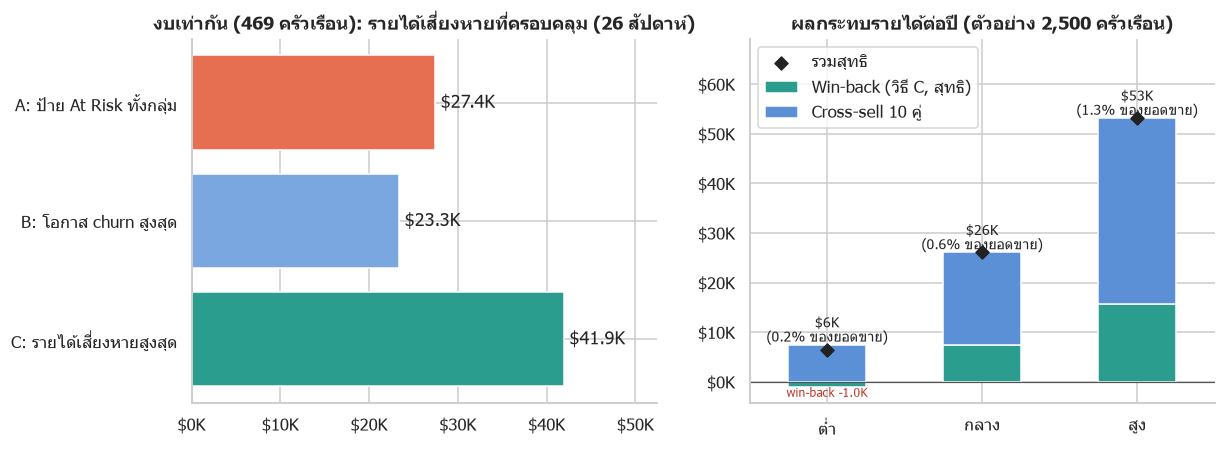

,"Win-back (วิธี C, สุทธิ)",Cross-sell 10 คู่,รวม,% ของยอดขายต่อปี
ต่ำ,-999.70,"7,486.60","6,486.90",0.20
กลาง,"7,380.60","18,716.60","26,097.20",0.60
สูง,"15,760.80","37,433.20","53,194.10",1.30


In [11]:
impact = pd.DataFrame({
    "Win-back (วิธี C, สุทธิ)": [wb.loc[("C", k), "สุทธิ (รายได้ − ต้นทุน) $"] for k in SAVE],
    "Cross-sell 10 คู่": [xs[k] for k in CONV],
}, index=list(SAVE))
impact["รวม"] = impact.sum(axis=1)
impact["% ของยอดขายต่อปี"] = impact["รวม"] / annual_sales * 100
impact.to_parquet(config.PROCESSED_DIR / "impact_scenarios.parquet")
target_tbl.to_parquet(config.PROCESSED_DIR / "winback_targeting.parquet")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
tt = target_tbl["revenue at risk 26 wk $"]
axes[0].barh(tt.index[::-1], tt.values[::-1], color=["#2a9d8f", "#7ba7e0", "#e76f51"])
for i, v in enumerate(tt.values[::-1]):
    axes[0].text(v, i, f" ${v / 1e3:.1f}K", va="center")
axes[0].set_title(f"งบเท่ากัน ({n} ครัวเรือน): รายได้เสี่ยงหายที่ครอบคลุม (26 สัปดาห์)")
axes[0].set_xlim(0, tt.max() * 1.25)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1e3:.0f}K"))
impact[["Win-back (วิธี C, สุทธิ)", "Cross-sell 10 คู่"]].plot.bar(stacked=True, ax=axes[1], color=[ACCENT, PRIMARY], rot=0)
pos_top = impact[["Win-back (วิธี C, สุทธิ)", "Cross-sell 10 คู่"]].clip(lower=0).sum(axis=1)   # ยอดบวกที่ซ้อนกัน (win-back อาจติดลบ)
for i, (v, p) in enumerate(zip(impact["รวม"], impact["% ของยอดขายต่อปี"])):
    axes[1].text(i, pos_top.iloc[i], f"${v / 1e3:.0f}K\n({p:.1f}% ของยอดขาย)", ha="center", va="bottom", fontsize=9)
axes[1].set_title("ผลกระทบรายได้ต่อปี (ตัวอย่าง 2,500 ครัวเรือน)")
neg_bottom = impact[["Win-back (วิธี C, สุทธิ)", "Cross-sell 10 คู่"]].clip(upper=0).sum(axis=1)   # ส่วนติดลบของ win-back
axes[1].axhline(0, color="#555", lw=0.8)
axes[1].scatter(range(len(impact)), impact["รวม"], marker="D", color="#222", zorder=5, label="รวมสุทธิ")
for i, nb_ in enumerate(neg_bottom):
    if nb_ < 0:
        axes[1].text(i, nb_, f"win-back {nb_ / 1e3:.1f}K", ha="center", va="top", fontsize=8, color="#c0392b")
axes[1].set_ylim(min(neg_bottom.min() * 3, -pos_top.max() * 0.08), pos_top.max() * 1.3)
axes[1].legend(loc="upper left")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1e3:.0f}K"))
save(fig, "07_impact_scenarios")
plt.show()
impact.round(1)

**อ่านผลกระทบ:** ผลรวมที่เป็นไปได้ ~$6K–53K ต่อปี (**0.2–1.3% ของยอดขาย**) ของตัวอย่างนี้ — ไม่ใช่ตัวเลขใหญ่
- ต้นทุน win-back (~$9K/ปี) เป็นเพียง ~1% ของส่วนลดหน้าร้านที่จ่ายอยู่แล้ว ($696K/ปี)
- **win-back ไม่ได้คุ้มเสมอ:** ที่ save rate 10% ขาดทุนทั้งสองวิธี (A −$3.9K, C −$1.0K) · คุ้มเมื่อ save rate ถึง ~20% (A +$1.6K, C +$7.4K)
- จุดคุ้มทุนของวิธี C อยู่ที่ save rate ~11% เทียบกับวิธี A ~17% → **เลือกคนตามยอดที่จะหายไป ทำให้คุ้มได้ที่ save rate ต่ำกว่า**
- **ยังไม่มีหลักฐานว่า save rate จริงเป็นเท่าไร** (campaign lift ที่วัดได้ไม่ต่างจากศูนย์) จึงต้องทดสอบ holdout ก่อนขยาย

## 4. Key Insights

| # | Insight | หลักฐาน | ความหมายต่อธุรกิจ |
|---|---|---|---|
| 1 | **รายได้กระจุกตัวและโตช้า** | top 20% = 53% ของยอด · โต ~6% ครึ่งหลังเทียบครึ่งแรก | โตด้วยการรักษาและเพิ่มมูลค่าลูกค้าเดิม ไม่ใช่ลดราคาแข่ง |
| 2 | **Champions 37% ทำยอด 71% และเสถียรที่สุด** แต่ ~13% หลุดไป At Risk ใน ~10 เดือน | forward validation (notebook 03) | ปกป้อง Champions และจับสัญญาณคนที่เริ่มห่างตั้งแต่เนิ่น ๆ |
| 3 | **ป้าย At Risk ไม่แม่นพอ — โมเดล churn ดีกว่า** (แต่ชนะ recency แบบง่ายเพียงเล็กน้อย) | ทดสอบ 2 สัปดาห์ งบเท่ากัน: แม่น 18–25% → 30% (ต่างอย่างมีนัยสำคัญ) · เทียบ recency เพิ่ม ~3 จุด · ROC-AUC 0.75–0.79 · 12% ของคนเสี่ยงสุดเป็น Loyal/Champions ที่ป้ายมองไม่เห็น | ใช้คะแนน churn เลือกคนแทนป้ายกลุ่ม |
| 4 | **ต้องเลือกคนตาม "ยอดที่จะหายไป" ไม่ใช่แค่ "โอกาส churn"** | คนโอกาส churn สูงสุดใช้จ่ายแค่ ~$7/สัปดาห์ · ผลจริงในชุด test 2 สัปดาห์ งบเท่ากัน: วิธี C ครอบคลุมยอดที่หายไปจริง 50–64% เทียบ 26–27% (ป้าย At Risk) และ 28–31% (เลือกตามยอดซื้ออย่างเดียว) | เลือกคนตามมูลค่า ทำให้ win-back คุ้มที่ save rate ต่ำกว่า |
| 5 | **แคมเปญกระจุกที่ Champions** และ 73% ของผู้ได้รับไม่เคยใช้คูปอง | 74% ของการส่งไป Champions | งบแคมเปญไม่ได้ไปหาคนที่ต้องการแรงจูงใจ |
| 6 | **ยังยืนยันไม่ได้ว่าแคมเปญเพิ่มยอดซื้อ** | lift +$0.76/ครัวเรือน/สัปดาห์ (95% CI −0.4 ถึง +1.9) ผ่าน placebo test | ทุกแคมเปญต่อจากนี้ต้องมี holdout · ตั้งเป้าไม่เกินที่ CI รองรับ (~3%) |
| 7 | **ส่วนลดหน้าร้านเป็นต้นทุนก้อนใหญ่และหว่าน** | ~$696K/ปี (15% ของราคาเต็ม) เทียบคูปอง ~$16K/ปี · ทุกกลุ่มได้เท่ากัน | แหล่งงบสำหรับข้อเสนอเฉพาะกลุ่ม |
| 8 | **ลูกค้าซื้อเป็น "มื้อ" และรูปแบบนี้คงที่** | 980 คู่ lift ≥ 1.5 · พาสต้า+ซอส lift 9.9 · 100% ของคู่ยังเสถียรในปีที่สอง · เหมือนกันทุกกลุ่ม | วางโปรขายคู่ล่วงหน้าได้ ไม่ต้องแยกตามกลุ่ม |
| 9 | **โอกาสขายคู่สูงสุดมีเนื้อสัตว์/อาหารแช่แข็งเป็นตัวเติม** | ผักกระป๋อง→เนื้อวัว, อาหารแช่แข็ง→พิซซ่า · 10 คู่แนะนำ attach rate 34% | โปร "ชุดมื้อเย็น" GROCERY + MEAT ช่วง 15–19 น. |
| 10 | **ผลที่คาดได้อยู่ที่ 0.2–1.3% ของยอดขายต่อปี และ win-back อาจขาดทุนถ้า save rate ต่ำ** | scenario ข้อ 3 | คุณค่าหลักอยู่ที่ความแม่นในการใช้งบและการวัดผล ไม่ใช่การเพิ่มยอดก้อนใหญ่ |

## 5. กลยุทธ์ที่เสนอ

**ทิศทาง:** เลิก "ลดราคาแบบหว่าน" → **"เลือกคน · เลือกข้อเสนอ · วัดผลด้วย holdout"**

### 4 เสาหลัก
| เสา | ทำอะไร | ใช้ผลวิเคราะห์จาก |
|---|---|---|
| **1. ปกป้อง Champions** | สิทธิพิเศษสมาชิก (ไม่ใช่ส่วนลดเพิ่ม) · เฝ้าดูคะแนน churn รายสัปดาห์ แจ้งเตือนเมื่อ Champions คะแนนพุ่ง | Segmentation, Churn |
| **2. Win-back ตามมูลค่า** | ส่งข้อเสนอดึงกลับให้คนที่ *รายได้เสี่ยงหาย* สูงสุด (วิธี C) · คนเสี่ยงแต่มูลค่าต่ำได้แค่ข้อความดิจิทัล · คนที่หายไปแล้ว (286 ครัวเรือน) ใช้แคมเปญ reactivation ต้นทุนต่ำ | Churn, CLV |
| **3. ขายคู่แบบ "ชุดมื้อ"** | โปรชุดมื้อเย็น GROCERY + MEAT (พาสต้า+ซอส+เนื้อ, ผัก+เนื้อ, แช่แข็ง+พิซซ่า) ช่วง 15–19 น. · จัดวางสินค้าคู่ใกล้กัน · คูปองหมวด B ให้คนที่ซื้อ A ประจำ | Market Basket, EDA |
| **4. ย้ายงบส่วนลดหว่าน** | ย้ายส่วนลดหน้าร้าน 5–10% ไปเป็นงบเสา 1–3 · **ทุกแคมเปญมี holdout 10–20%** · วัดยอดส่วนเพิ่ม ไม่ใช่อัตราใช้คูปอง | Pricing, Campaign |

### STP ต่อกลุ่ม
| กลุ่ม | เป้าหมาย | ข้อเสนอ | ช่องทาง |
|---|---|---|---|
| **Champions** (37%) | รักษา + เพิ่มมูลค่าตะกร้า | สิทธิพิเศษสมาชิก · โปรชุดมื้อ · แจ้งเตือนเมื่อคะแนน churn สูง | แอป/บัตรสมาชิก, หน้าร้าน |
| **Loyal** (26%) | เพิ่มความถี่ | คูปอง "ซื้อครบ X ครั้งใน 4 สัปดาห์" ในหมวดประจำ · โปรชุดมื้อ | แอป, อีเมล |
| **At Risk** (23%) | ดึงกลับเฉพาะคนที่เสี่ยงและมีมูลค่า | วิธี C: ข้อเสนอ GROCERY/MEAT · คะแนนต่ำ: ข้อความเตือนความจำ | ไปรษณีย์/แอป (คนมูลค่าสูง), ดิจิทัล (ที่เหลือ) |
| **Occasional** (14%) | ต้นทุนต่ำ | อีเมล/แอปเท่านั้น · ไม่ใช้ส่วนลดแรง | ดิจิทัล |

## 6. Action Plan

| ระยะ | ช่วงเวลา | กิจกรรม | ผู้รับผิดชอบ | ผลลัพธ์ | เงื่อนไขไปต่อ |
|---|---|---|---|---|---|
| **0 · Foundation** | เดือน 0–1 | ตั้ง pipeline อัปเดตกลุ่มลูกค้าและคะแนน churn รายสัปดาห์ · ออกแบบ holdout (สุ่ม 10–20%) · Dashboard ติดตามกลุ่ม/KPI | Data | คะแนนรายสัปดาห์ + Dashboard | pipeline รันได้ทุกสัปดาห์ · ตัวเลขตรงกับ notebook |
| **1 · Pilot** | เดือน 1–3 | (ก) Win-back วิธี C ~470 ครัวเรือน เทียบ holdout (ข) โปรชุดมื้อ 3 คู่แรก ในบางสาขา/บางครัวเรือน เทียบกลุ่มควบคุม (ค) สิทธิพิเศษ Champions | CRM + Merchandising | ผล incremental ต่อแคมเปญ | ยอดส่วนเพิ่ม > ต้นทุน และ CI ไม่คร่อม 0 |
| **2 · Scale** | เดือน 4–6 | ขยายสิ่งที่ผ่าน pilot · ย้ายส่วนลดหน้าร้าน 5% ไปเป็นงบเฉพาะกลุ่ม (ทดลองบางสาขาก่อน) · ทดสอบคูปองความถี่ของ Loyal · reactivation ดิจิทัลสำหรับคนที่หายไปแล้ว | Marketing + Pricing | แผนงบโปรโมชันใหม่ | ยอดขายสาขาทดลองไม่ลดเกินช่วงที่ยอมรับ |
| **3 · Optimize** | เดือน 7–12 | trigger อัตโนมัติเมื่อคะแนน churn พุ่ง · retrain โมเดลทุกไตรมาส · เพิ่มข้อมูลกำไรเข้า CLV · ใช้ผล holdout สร้าง uplift model (เลือกคนที่ *ตอบสนอง* ต่อข้อเสนอ ไม่ใช่แค่เสี่ยง) | Data + CRM | ระบบ always-on | ROI ของงบโปรโมชันเป็นบวกทุกไตรมาส |

## 7. KPI / Target (12 เดือน)
baseline มาจากตาราง KPI ข้อ 2 · target เป็นค่าที่เสนอ อิงจาก scenario กลาง และ **ไม่สูงเกินที่ข้อมูลรองรับ** (เช่น lift ของแคมเปญ CI สูงสุด ~3%)

| KPI | Baseline | Target | วิธีวัด | ความถี่ |
|---|---|---|---|---|
| Churn rate ของกลุ่มที่ได้ win-back | 13% (ทั้งฐาน) | **ลด 20%** เทียบ holdout (save rate กลาง) | treated vs holdout | ทุก 8 สัปดาห์ |
| ยอดที่หายไปของคน churn ที่ครอบคลุมด้วยงบ win-back | 26% (ป้าย At Risk, ผลจริงในชุด test) | **≥ 45%** (วิธี C) | เทียบยอดจริงของคน churn กับกลุ่มที่ส่ง | ทุก 8 สัปดาห์ |
| ความแม่นของการเลือกคน (precision) | 22% (ป้าย At Risk, เฉลี่ย 2 สัปดาห์ทดสอบ) | **≥ 30%** (รักษาระดับที่โมเดลทำได้) | churn จริงในคนที่ส่ง | ทุก 8 สัปดาห์ |
| Champions ที่ตกไป At Risk | 13% / ~10 เดือน | **≤ 10%** | migration รายไตรมาส | รายไตรมาส |
| มูลค่าตะกร้า Champions | $31.3 | **+2%** เทียบ holdout | treated vs holdout | รายเดือน |
| ความถี่ซื้อ Loyal | 0.62 ครั้ง/สัปดาห์ | **+5%** เทียบ holdout | treated vs holdout | รายเดือน |
| Attach rate คู่สินค้าโปรชุดมื้อ | 34% | **+2 pp** ในคู่ที่ทำโปร | สาขา/ครัวเรือนทดลอง vs ควบคุม | ราย 4 สัปดาห์ |
| สัดส่วนการส่งแคมเปญไป Champions | 74% | **≤ 55%** | campaign log | รายไตรมาส |
| ผู้ได้แคมเปญที่ไม่เคยใช้คูปอง | 73% | **≤ 60%** | redemption log | รายไตรมาส |
| ส่วนลดหน้าร้าน ÷ ราคาเต็ม | 15.3% | **≤ 14.5%** (ย้าย ~5%) โดยยอดไม่ลดเกิน CI | ยอดขายสาขาทดลอง | รายเดือน |
| แคมเปญที่มี holdout | 0% | **100%** | campaign log | ทุกแคมเปญ |
| รายได้ส่วนเพิ่มจากโปรแกรม | — | **≥ 0.6% ของยอดขาย/ปี** (scenario กลาง) | รวมผล holdout ทุกแคมเปญ | รายไตรมาส |

## 8. ข้อจำกัด
- **ไม่มีต้นทุน/กำไร** — CLV และผลกระทบเป็นรายได้ ไม่ใช่กำไร · ต้นทุนข้อเสนอ ($10/ครัวเรือน) เป็นสมมติฐาน
- **ข้อมูลประชากรมีแค่ 32% และเอนเอียง** ไปทาง Champions (Occasional ไม่มีเลย) จึงไม่ใช้ในโมเดล
- **ผลแคมเปญมาจากข้อมูลย้อนหลัง** ไม่ใช่การทดลองแบบสุ่ม และ 30 แคมเปญทับซ้อนกัน → ประมาณผลได้แค่ช่วงกว้าง
- **Market Basket แสดงแค่การซื้อคู่กัน** ไม่ใช่ผลของโปร · ระดับหมวด (COMMODITY) ไม่ใช่ราคา/ยี่ห้อ
- **Churn เป็นแบบลดยอดมาก** ไม่ใช่การเลิกเป็นสมาชิก (ไม่มีข้อมูลนั้น) · โมเดลบอก *ใครเสี่ยง* ไม่ได้บอก *ใครจะตอบสนองต่อข้อเสนอ* · ให้คะแนนสูงกว่าอัตราจริง ~9% (ปรับแล้ว) และชนะ baseline recency เพียงเล็กน้อย
- **ข้อมูลเป็นตัวอย่างของ dunnhumby** (2,500 ครัวเรือน, ~2 ปี) ไม่ใช่ข้อมูล Tesco US จริง · ตัวเลขดอลลาร์ใช้ดูขนาดเปรียบเทียบ
- **ไม่มีข้อมูลความพึงพอใจ (Satisfaction/NPS)** จึงใช้ RFM/CLV แทน · ควรเก็บ NPS ควบคู่ในระยะ Pilot